### 💡 단변량 분석 (Univariate Analysis)
단변량 분석은 하나의 변수(컬럼)을 분석하는 방법이다.

타이타닉 데이터셋에서는 아래와 같이 분석할 수 있다.
- age : 승객들의 나이는 어떤 분포를 보일까
- fare : 승객들의 요금은 어느 구간에서 집중돼어있을까
- sex : 어떤 성별이 더 배에 많이 탑승했을까
- pclass : 각 객실 등급의 승객은 몇명일까
- survived : 생존자와 사망자의 비율은 어떻게 될까

여기서 **단변량 분석**의 포인트는 변수 하나의 특성을 파악하는 것이다. 두 변수간의 특성을 파악하는건 **이변량 분석**이라고 한다.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Mac 한글 폰트 설정
plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

# 데이터 불러오기
df = pd.read_csv("./datasets/titanic.csv")

# 데이터 확인
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [5]:
# 나이 기초 통계량
print("평균 :", df["age"].mean())
print("중앙값 :", df["age"].median())
print("최대값 :", df["age"].max())
print("최소값 :", df["age"].min())
print("최빈값 :", df["age"].mode().iloc[0])

평균 : 29.69911764705882
중앙값 : 28.0
최대값 : 80.0
최소값 : 0.42
최빈값 : 24.0


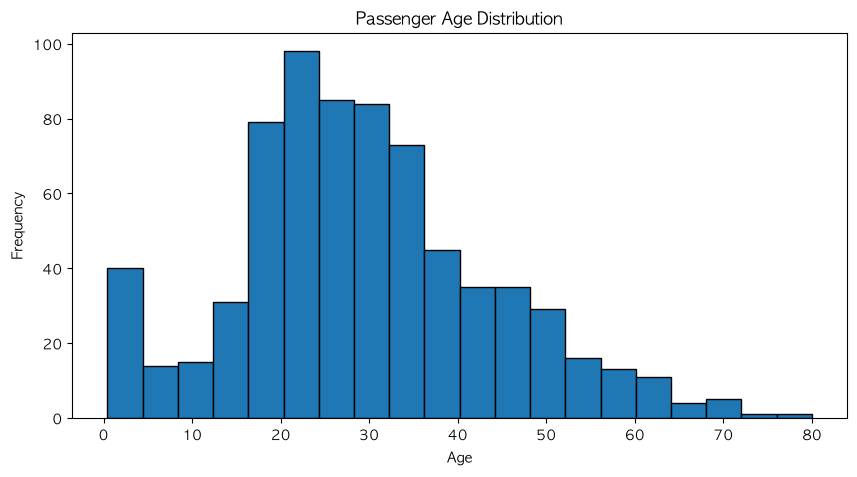

In [6]:
# 히스토그램으로 분포 확인하기
plt.figure(figsize=(10, 5))

plt.hist(
    df["age"].dropna(),
    bins=20,
    edgecolor="black"
)

plt.title("Passenger Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

히스토그램으로 전체적인 분포를 확인했다면, 박스플롯으로는 이상치 탐지, 중앙값, 사분위수를 집중적으로 확인할 수 있다.

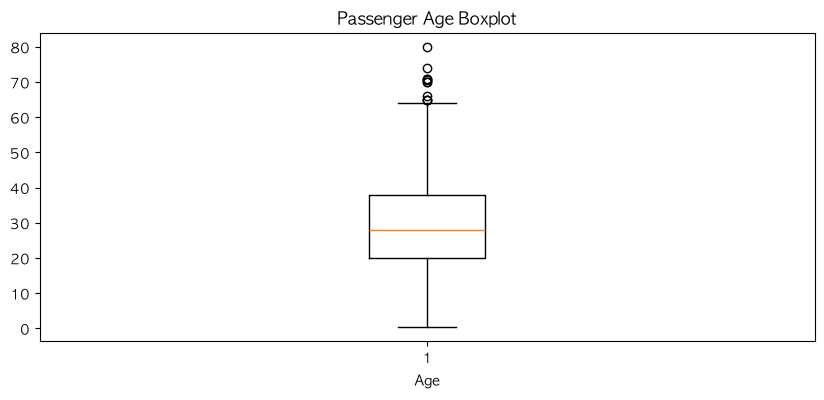

In [7]:
# 박스플롯으로 확인하기
plt.figure(figsize=(10, 4))

plt.boxplot(
    df["age"].dropna(),
)

plt.title("Passenger Age Boxplot")
plt.xlabel("Age")

plt.show()

이번엔 범주형 변수 단변량을 분석해보겠다.

In [11]:
# 성별 별 승객 수
# value_counts() : 범주별로 갯수를 출력한다.
print(df["sex"].value_counts())

# value_counts(normalize=True) : 범주별 비율을 출력해준다.
# 퍼센트로 보고 싶으면 * 100 해주기
print(df["sex"].value_counts(normalize=True))
print(df["sex"].value_counts(normalize=True) * 100)

sex
male      577
female    314
Name: count, dtype: int64
sex
male      0.647587
female    0.352413
Name: proportion, dtype: float64
sex
male      64.758698
female    35.241302
Name: proportion, dtype: float64


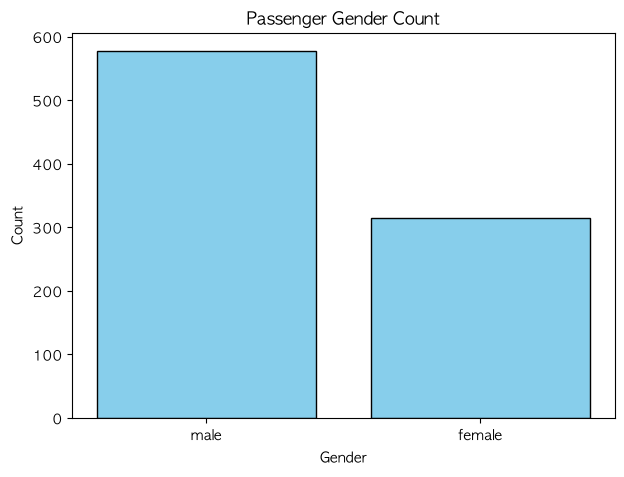

In [15]:
# 막대그래프로 시각화
sex_count = df["sex"].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(
    sex_count.index,
    sex_count.values,
    color="skyblue",
    edgecolor="black"
)

plt.title("Passenger Gender Count")
plt.xlabel("Gender")
plt.ylabel("Count")

plt.show()

---
#### 실습문제

29.69911764705882
28.0
0.42
80.0
32.204207968574636
14.4542
49.6934285971809


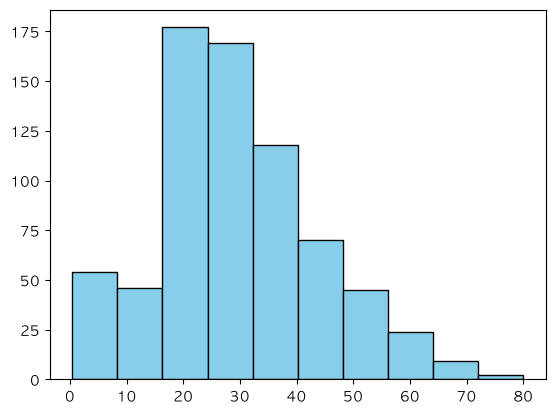

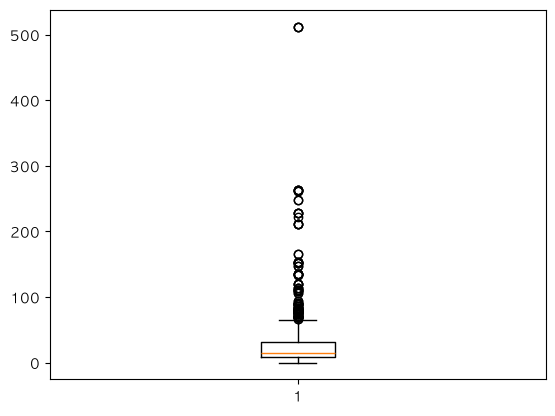

In [29]:
# A. 수치형 변수 분석
# 1. age의 평균, 중앙값, 최솟값, 최댓값을 출력
print(df["age"].mean())
print(df["age"].median())
print(df["age"].min())
print(df["age"].max())

# 2. fare의 평균, 중앙값, 표준편차를 출력
print(df["fare"].mean())
print(df["fare"].median())
print(df["fare"].std())

# 3. age의 히스토그램을 확인
plt.hist(
    df["age"].dropna(),
    color="skyblue",
    edgecolor="black"
    )

plt.show()


# 4. fare의 박스플롯을 확인
plt.boxplot(
    df["fare"].dropna()
)

plt.show()

sex
male      577
female    314
Name: count, dtype: int64
sex
male      64.758698
female    35.241302
Name: proportion, dtype: float64
survived
0    549
1    342
Name: count, dtype: int64


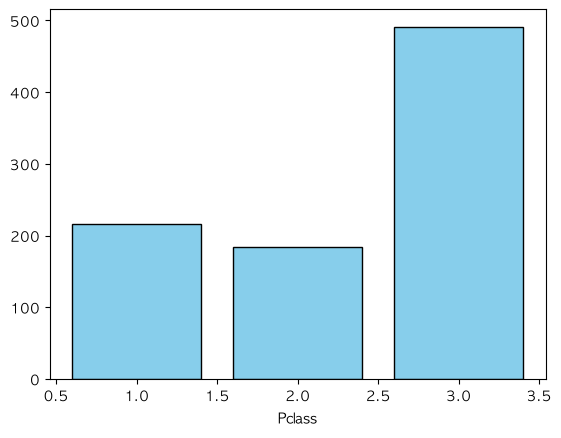

In [35]:
# B. 범주형 변수 분석
# 1. sex의 범주별 승객 수를 출력
print(df["sex"].value_counts())

# 2. sex의 범주별 비율을 백분율로 출력
print(df["sex"].value_counts(normalize=True) * 100)

# 3. survived의 생존 여부별 승객 수를 출력
print(df["survived"].value_counts())

# 4. pclass의 객실 등급별 승객 수를 막대그래프로 확인
pclass_count = df["pclass"].value_counts()

plt.bar(
    pclass_count.index,
    pclass_count.values,
    color="skyblue",
    edgecolor="black"
)

plt.xlabel("Pclass")

plt.show()

C. 분석 및 해석
- 평균과 중앙값의 차이가 크다는 것은 무엇을 의미할 수 있을까?
    > 평균이 중앙값보다 크게 나타난다면 오른쪽으로 꼬리가 긴 양의 왜도 분포일 가능성이 있다
- fare에서 평균보다 중앙값이 작다면 어떤 분포를 의심할 수 있을까?
    > 작은 운임을 가진 승객이 많을 가능성이 크다.
- 범주형 데이터 분석에서 평균보다 빈도수와 비율이 유용한 이유는 무엇일까?
    > 카테고리가 딱 나뉘어져 있고 그 카테고리마다 수치가 얼마다 되는지 정할 수 있어서 빈도수와 비율이 더 유용하다.
- 히스토그램과 박스플롯은 각각 어떤 정보를 파악하는 데 적합할까?
    > 히스토그램은 수치형 데이터들의 분포를 파악하기 좋고, 박스플롯은 분포도, 이상치 등을 파악하는데 좋다.